# Primer Parcial - INF672 Machine Learning

**Nombre:** Aviles Melchor Abimael Metzraim

**Materia:** INF672 - Machine Learning  

**Fecha:** 16/09/2026

## Ejercicio 01 - Una probabilidad de dos maneras

In [189]:
import itertools

# 1. Valor exacto (por conteo)
pares_posibles = list(itertools.product(range(1, 7), repeat=2))
favorables = [par for par in pares_posibles if 6 in par]

probabilidad = len(favorables) / len(pares_posibles)

print("Pares posibles:", len(pares_posibles))
print("Casos favorables:", len(favorables))
print("Probabilidad exacta:", probabilidad)

Pares posibles: 36
Casos favorables: 11
Probabilidad exacta: 0.3055555555555556


### Interpretación

Existen 36 combinaciones posibles y 11 tienen al menos un 6. Por eso, la probabilidad exacta es **11/36 ≈ 0.3056**.

In [190]:
import numpy as np

# 2. Estimación (por simulación)
N = 100000

rng = np.random.default_rng(42)

tiradas = rng.integers(1, 7, size=(N, 2))
tienen_seis = np.any(tiradas == 6, axis=1)

estimacion = tienen_seis.mean()

print("Número de tiradas:", N)
print("Estimación:", estimacion)

Número de tiradas: 100000
Estimación: 0.3057


### Interpretación

La estimación obtenida es cercana al valor exacto de 0.3056. Esto muestra que al hacer muchas tiradas, la frecuencia del evento se acerca a la probabilidad real.

In [191]:
import pandas as pd

# 3. Convergencia
tasas = [100, 1000, 100000]
resultados = []

for N in tasas:
    tiradas = rng.integers(1, 7, size=(N, 2))
    tienen_seis = np.any(tiradas == 6, axis=1)

    estimacion = tienen_seis.mean()
    error = abs(estimacion - probabilidad)

    resultados.append([N, estimacion, error])

tabla_error = pd.DataFrame(
    resultados,
    columns=["N", "Estimación", "Error absoluto"]
)

tabla_error

,N,Estimación,Error absoluto
0,100,0.34000,0.034444
1,1000,0.31300,0.007444
2,100000,0.30463,0.000926


### Interpretación

Se puede observar que al aumentar el número de tiradas, la estimación generalmente se acerca más al valor exacto. Con pocas tiradas existe mayor variación en la estimación, mientras que con 100.000 tiradas el resultado es más estable.

## Ejercicio 02 - Perfil estadístico por especie y limpieza de datos

In [192]:
from sklearn.datasets import load_iris

# 1. Perfil por especie

iris = load_iris(as_frame=True)
df = iris.frame

# Cambiar el número de especie por su nombre
nombres_especies = dict(enumerate(iris.target_names))
df["species"] = df["target"].map(nombres_especies)

caracteristicas = [
    "sepal length (cm)",
    "sepal width (cm)",
    "petal length (cm)",
    "petal width (cm)"
]

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [193]:
# Media, mediana, desviación estándar y cuartiles
estadisticos = df.groupby("species")[caracteristicas].agg(
    ["mean", "median", "std", "quantile"]
)

estadisticos

sepal length (cm)                           sepal width (cm)  \
                        mean median       std quantile             mean   
species                                                                   
setosa                 5.006    5.0  0.352490      5.0            3.428   
versicolor             5.936    5.9  0.516171      5.9            2.770   
virginica              6.588    6.5  0.635880      6.5            2.974   

                                     petal length (cm)                   \
           median       std quantile              mean median       std   
species                                                                   
setosa        3.4  0.379064      3.4             1.462   1.50  0.173664   
versicolor    2.8  0.313798      2.8             4.260   4.35  0.469911   
virginica     3.0  0.322497      3.0             5.552   5.55  0.551895   

                    petal width (cm)                            
           quantile             mean median       std quantile  
species                                                         
setosa         1.50            0.246    0.2  0.105386      0.2  
versicolor     4.35            1.326    1.3  0.197753      1.3  
virginica      5.55            2.026    2.0  0.274650      2.0

In [194]:
# Tabla más legible con Q1, Q2 y Q3
filas = []

for especie, grupo in df.groupby("species"):
    for caracteristica in caracteristicas:
        filas.append({
            "species": especie,
            "caracteristica": caracteristica,
            "media": grupo[caracteristica].mean(),
            "mediana": grupo[caracteristica].median(),
            "std": grupo[caracteristica].std(),
            "Q1": grupo[caracteristica].quantile(0.25),
            "Q2": grupo[caracteristica].quantile(0.50),
            "Q3": grupo[caracteristica].quantile(0.75)
        })

tabla_estadisticos = pd.DataFrame(filas)
tabla_estadisticos

,species,caracteristica,media,mediana,std,Q1,Q2,Q3
0,setosa,sepal length (cm),5.006,5.00,0.352490,4.800,5.00,5.200
1,setosa,sepal width (cm),3.428,3.40,0.379064,3.200,3.40,3.675
2,setosa,petal length (cm),1.462,1.50,0.173664,1.400,1.50,1.575
3,setosa,petal width (cm),0.246,0.20,0.105386,0.200,0.20,0.300
4,versicolor,sepal length (cm),5.936,5.90,0.516171,5.600,5.90,6.300
5,versicolor,sepal width (cm),2.770,2.80,0.313798,2.525,2.80,3.000
6,versicolor,petal length (cm),4.260,4.35,0.469911,4.000,4.35,4.600
7,versicolor,petal width (cm),1.326,1.30,0.197753,1.200,1.30,1.500
8,virginica,sepal length (cm),6.588,6.50,0.635880,6.225,6.50,6.900
9,virginica,sepal width (cm),2.974,3.00,0.322497,2.800,3.00,3.175


In [195]:
# 2. Faltantes
rng = np.random.default_rng(42)
df_limpio = df.copy()

for columna in caracteristicas:
    indices = rng.choice(df_limpio.index, size=3, replace=False)
    df_limpio.loc[indices, columna] = np.nan

print("Faltantes antes de imputar:")
print(df_limpio[caracteristicas].isna().sum())

# Imputar usando la mediana de cada característica dentro de cada especie
for columna in caracteristicas:
    df_limpio[columna] = df_limpio.groupby("species")[columna].transform(
        lambda x: x.fillna(x.median())
    )

print("\nFaltantes después de imputar:")
print(df_limpio[caracteristicas].isna().sum())

Faltantes antes de imputar:
sepal length (cm)    3
sepal width (cm)     3
petal length (cm)    3
petal width (cm)     3
dtype: int64

Faltantes después de imputar:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64


### Interpretación

Se usa la **mediana** porque es menos sensible a valores extremos que la media. Además, la imputación se hace por especie para mantener las diferencias entre ellas.

In [196]:
# 3. Lectura
medias_especie = df.groupby("species")[caracteristicas].mean()
medias_especie

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
species,,,,
setosa,5.006,3.428,1.462,0.246
versicolor,5.936,2.770,4.260,1.326
virginica,6.588,2.974,5.552,2.026


### Interpretación

La **longitud del pétalo** parece separar mejor las especies porque sus medias son bastante diferentes. La **anchura del sépalo** las confunde más porque sus medias son más parecidas.

Una característica con medias muy distintas permite distinguir mejor las especies, mientras que medias parecidas hacen que los valores se mezclen más.

## Ejercicio 03 - Tres formas de comparar dos flores

In [197]:
# 1. Tres funciones propias
def distancia_euclidiana(a, b):
    return np.sqrt(np.sum((a - b) ** 2))

def producto_punto(a, b):
    return np.sum(a * b)

def similitud_coseno(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

In [198]:
# 2. Elige cuatro flores
# 10 y 30 son de la especie setosa
# 70 pertenece a la especie versicolor
# 130 pertenece a la especie virginica
indices = [10, 30, 70, 130]

datos_flores = df.loc[indices, caracteristicas]
datos_flores

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
10,5.4,3.7,1.5,0.2
30,4.8,3.1,1.6,0.2
70,5.9,3.2,4.8,1.8
130,7.4,2.8,6.1,1.9


In [199]:
# 3. Comparar los pares
pares = [
    (10, 30),
    (10, 70),
    (10, 130),
    (70, 130)
]

resultados = []

for i, j in pares:
    a = df.loc[i, caracteristicas].to_numpy()
    b = df.loc[j, caracteristicas].to_numpy()

    resultados.append({
        "Par": f"{i} - {j}",
        "Distancia euclidiana": distancia_euclidiana(a, b),
        "Producto punto": producto_punto(a, b),
        "Similitud coseno": similitud_coseno(a, b)
    })

tabla_comparacion = pd.DataFrame(resultados)
tabla_comparacion

,Par,Distancia euclidiana,Producto punto,Similitud coseno
0,10 - 30,0.854400,39.83,0.998504
1,10 - 70,3.734970,51.26,0.903362
2,10 - 130,5.372150,59.85,0.875954
3,70 - 130,2.027313,85.32,0.993373


### Interpretación
La pareja **10 - 30**, que pertenece a la misma especie, tiene una distancia euclidiana pequeña y un coseno cercano a 1, por lo que son bastante parecidas.

La distancia euclidiana y el coseno no necesariamente ordenan las flores igual, porque miden cosas diferentes: la distancia considera la diferencia en los valores, mientras que el coseno se enfoca en la dirección de los vectores.

## Ejercicio 04 - Descenso de gradiente

In [200]:
import matplotlib.pyplot as plt

# 1. Programa el descenso
def descenso_gradiente(x_inicial, tasa, pasos):
    x = x_inicial
    trayectoria = [x]

    for _ in range(pasos):
        derivada = 2 * (x - 4)
        x = x - tasa * derivada
        trayectoria.append(x)

    return trayectoria

In [201]:
# 2. Prueba tres tasas de aprendizaje
tasas = [0.01, 0.1, 1.1]
trayectorias = {}

for tasa in tasas:
    trayectorias[tasa] = descenso_gradiente(10, tasa, 30)

resultados_finales = pd.DataFrame({
    "Tasa": tasas,
    "x final": [trayectorias[tasa][-1] for tasa in tasas],
    "Error respecto a 4": [abs(trayectorias[tasa][-1] - 4) for tasa in tasas]
})

resultados_finales

,Tasa,x final,Error respecto a 4
0,0.01,7.272906,3.272906
1,0.10,4.007428,0.007428
2,1.10,1428.257883,1424.257883


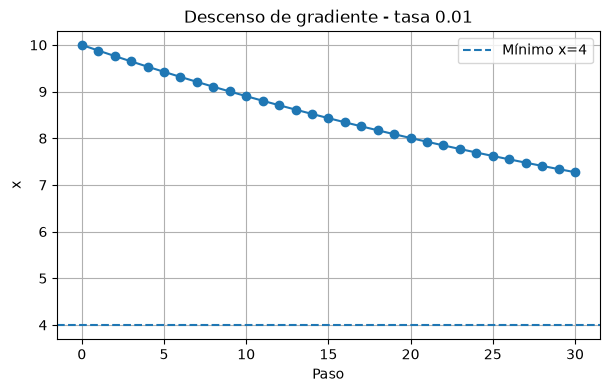

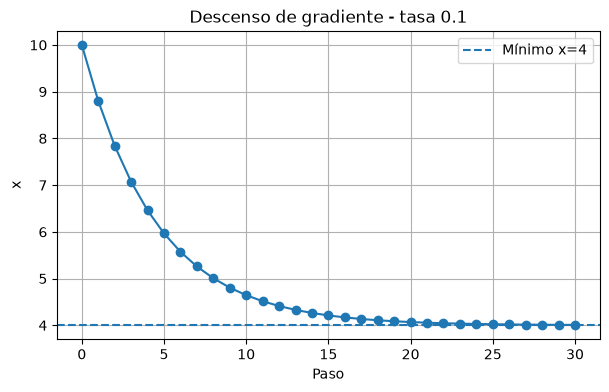

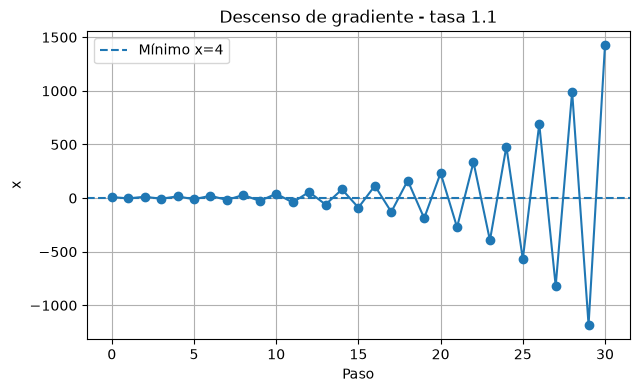

In [202]:
# Graficar la trayectoria de x para cada tasa
for tasa in tasas:
    plt.figure(figsize=(7, 4))
    plt.plot(range(len(trayectorias[tasa])), trayectorias[tasa], marker="o")
    plt.axhline(4, linestyle="--", label="Mínimo x=4")
    plt.title(f"Descenso de gradiente - tasa {tasa}")
    plt.xlabel("Paso")
    plt.ylabel("x")
    plt.legend()
    plt.grid()
    plt.show()

### 3. Compara el x final de cada tasa con el mínimo verdadero (x = 4)

* **¿Todas llegan cerca del mínimo?**  
No todas llegan al mínimo. Únicamente las tasas de **0.01** y **0.10** logran acercarse a $x = 4$, mientras que con **1.10** ocurre lo contrario y el algoritmo se aleja por completo.

* **Con $\eta = 0.01$:**  
Da pasos demasiado cortos y avanza lento; con 30 iteraciones aún no alcanza el mínimo, quedando en $x \approx 7.27$ con un error de $3.27$. Necesitaría muchos más pasos para converger.

* **Con $\eta = 0.1$:**  
Tiene un comportamiento óptimo y equilibrado. Desciende de forma constante en cada paso y converge rápidamente muy cerca del objetivo, terminando en $x \approx 4.007$ (error de apenas $0.007$).

* **Con $\eta = 1.1$:**  
La tasa es excesivamente grande para esta función. En cada actualización el paso se sobrepasa al lado opuesto y el error se va multiplicando, por lo que **oscila y se dispara (diverge)**. En vez de acercarse a 4, termina explotando hasta $x \approx 1428.26$.